# Best fitted line, and confidence region for the parameters

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t, f

In [2]:
dat = np.array([
    [100, 89, 89, 92, 78, 101, 90, 82, 95, 108, 111, 112, 125, 123, 100, 102, 112, 112, 100, 107, 103, 129, 118, 149],
    [709, 740, 586, 806, 694, 760, 664, 509, 619, 652, 772, 896, 742, 831, 667, 772, 838, 679, 889, 690, 698, 860, 799, 882]]).T

dat = dat/10

n = len(dat)
Y = dat[:,1]
X = np.column_stack([np.ones(n),dat[:,0]])
p = X.shape[1]

In [3]:
# We compute the coeff.
beta = np.linalg.lstsq(X, Y, rcond=None)[0]

# Calculate the SSE
SSE = np.linalg.lstsq(X, Y, rcond=None)[1][0]

Computing confidence and prediction intervals

In [4]:
alpha = 0.05
x_grid = np.linspace(7, 15, 50)
X_grid = np.array([np.ones(len(x_grid)),x_grid]).T

Y_grid_hat = X_grid @ beta

In [5]:
# Computing confidence interval
aux_t_conf = np.sqrt(SSE/(n-p)*(np.diag(X_grid @ np.linalg.inv(X.T @ X) @ X_grid.T)))
ci_lower = Y_grid_hat-t.ppf(1-alpha/2,n-p)*aux_t_conf
ci_upper = Y_grid_hat+t.ppf(1-alpha/2,n-p)*aux_t_conf

# Computing prediction interval
aux_t_pred = np.sqrt(SSE/(n-p)*(1+np.diag(X_grid @ np.linalg.inv(X.T @ X) @ X_grid.T)))
pi_lower = Y_grid_hat-t.ppf(1-alpha/2,n-p)*aux_t_pred
pi_upper = Y_grid_hat+t.ppf(1-alpha/2,n-p)*aux_t_pred

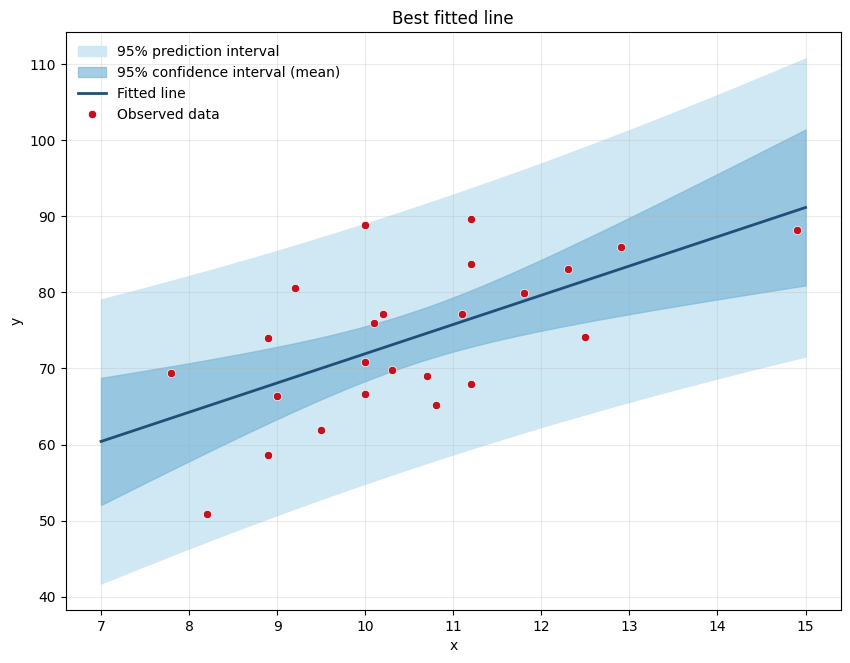

In [6]:
plt.figure(figsize=(10,7.5))

# Bands: light, low-saturation fills, ordered wide-to-narrow
ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
plt.fill_between(x_grid, pi_lower, pi_upper, color='#cfe8f3', label=pi_label)
plt.fill_between(x_grid, ci_lower, ci_upper, color='#7fb8d8', alpha=0.7, label=ci_label)

# Fitted curve as a line, not markers — it's a model, not observations
plt.plot(x_grid, beta[0]+beta[1]*x_grid, color='#1f4e79', lw=2, label='Fitted line')

# Observed data on top, dark and distinct
plt.plot(dat[:,0], Y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Best fitted line')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

Computing confidence intervals and confidence regions for the parameters $\beta$

In [7]:
aux_t_conf = np.sqrt(SSE/(n-p)*(np.diag(np.linalg.inv(X.T @ X))))

beta_0_upp = beta[0]+t.ppf(1-alpha/2,n-p)*aux_t_conf[0]
beta_0_low = beta[0]-t.ppf(1-alpha/2,n-p)*aux_t_conf[0]

beta_1_upp = beta[1]+t.ppf(1-alpha/2,n-p)*aux_t_conf[1]
beta_1_low = beta[1]-t.ppf(1-alpha/2,n-p)*aux_t_conf[1]

def conf_region(b0, b1):
    # (b-beta)' X'X (b-beta) (n-p)/(p SSE), it works with numbers or with grids
    A = X.T @ X
    d0 = b0-beta[0]
    d1 = b1-beta[1]
    return (n-p)/(p*SSE)*(A[0,0]*d0**2 + 2*A[0,1]*d0*d1 + A[1,1]*d1**2)

beta_0_vect = np.linspace(0, 70, 400)
beta_1_vect = np.linspace(0.5, 7.5, 400)

# z has one row for each value of beta_1 and one column for each value of beta_0, as plt.contour needs
beta_0_grid, beta_1_grid = np.meshgrid(beta_0_vect, beta_1_vect)
z = conf_region(beta_0_grid, beta_1_grid)
level = f.ppf(1-alpha, p, n-p)

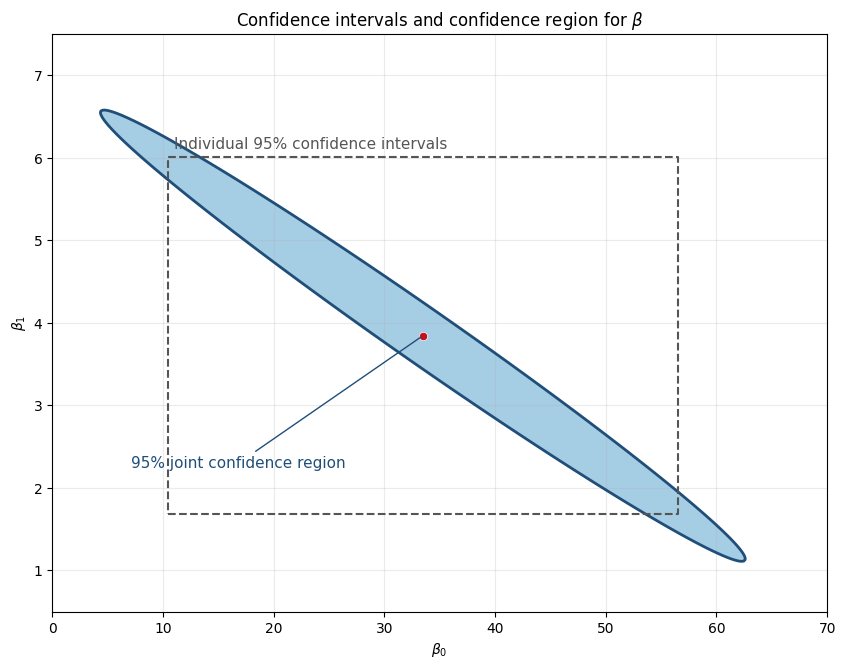

In [8]:
plt.figure(figsize=(10,7.5))
conf = f'{(1 - alpha) * 100:.0f}%'

plt.contourf(beta_0_grid, beta_1_grid, z, levels=[0, level], colors=['#7fb8d8'], alpha=0.7)
plt.contour(beta_0_grid, beta_1_grid, z, levels=[level], colors=['#1f4e79'], linewidths=2)
plt.plot(
    [beta_0_low,beta_0_upp,beta_0_upp,beta_0_low,beta_0_low],
    [beta_1_low,beta_1_low,beta_1_upp,beta_1_upp,beta_1_low],
    '--', color='#555555', lw=1.5)
plt.plot(beta[0], beta[1], 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5)

plt.annotate(f'{conf} joint confidence region', (beta[0], beta[1]), xytext=(-210, -95), textcoords='offset points',
             color='#1f4e79', fontsize=11, arrowprops=dict(arrowstyle='-', color='#1f4e79', lw=1))
plt.annotate(f'Individual {conf} confidence intervals', (beta_0_low, beta_1_upp), xytext=(4, 6),
             textcoords='offset points', color='#555555', fontsize=11)

plt.xlabel(r'$\beta_0$')
plt.ylabel(r'$\beta_1$')
plt.title(r'Confidence intervals and confidence region for $\beta$')
plt.grid(True, alpha=0.25)

The estimators of the intercept and the slope are negatively correlated: the ellipse is tilted downwards. The rectangle built with the individual intervals contains values of $\beta$ that are not plausible (its upper right and lower left corners) and leaves out plausible ones (the tips of the ellipse).